<a href="https://colab.research.google.com/github/Huzaif005/Machine-Learning-External-/blob/main/Practical_2_Principal_Component_Analysis_(PCA).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [5]:
import pandas as pd

df = pd.read_csv("wine-quality-white-and-red.csv")

print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())

    type  fixed acidity  volatile acidity  citric acid  residual sugar  \
0  white            7.0              0.27         0.36            20.7   
1  white            6.3              0.30         0.34             1.6   
2  white            8.1              0.28         0.40             6.9   
3  white            7.2              0.23         0.32             8.5   
4  white            7.2              0.23         0.32             8.5   

   chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  \
0      0.045                 45.0                 170.0   1.0010  3.00   
1      0.049                 14.0                 132.0   0.9940  3.30   
2      0.050                 30.0                  97.0   0.9951  3.26   
3      0.058                 47.0                 186.0   0.9956  3.19   
4      0.058                 47.0                 186.0   0.9956  3.19   

   sulphates  alcohol  quality  
0       0.45      8.8        6  
1       0.49      9.5        6  
2       0.4

In [8]:
# Load the downloaded CSV file
df = pd.read_csv("wine-quality-white-and-red.csv")

# Display first 5 rows
print("Wine Quality Dataset:")
print(df.head())

# Display dataset information
print("\nDataset Shape:")
print(df.shape)

print("\nDataset Columns:")
print(df.columns)

Wine Quality Dataset:
    type  fixed acidity  volatile acidity  citric acid  residual sugar  \
0  white            7.0              0.27         0.36            20.7   
1  white            6.3              0.30         0.34             1.6   
2  white            8.1              0.28         0.40             6.9   
3  white            7.2              0.23         0.32             8.5   
4  white            7.2              0.23         0.32             8.5   

   chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  \
0      0.045                 45.0                 170.0   1.0010  3.00   
1      0.049                 14.0                 132.0   0.9940  3.30   
2      0.050                 30.0                  97.0   0.9951  3.26   
3      0.058                 47.0                 186.0   0.9956  3.19   
4      0.058                 47.0                 186.0   0.9956  3.19   

   sulphates  alcohol  quality  
0       0.45      8.8        6  
1       0.49      9.5 

In [9]:
# Identify the wine type column
type_col = None

for col in df.columns:
    if col.strip().lower() in ['type', 'wine_type', 'color', 'wine']:
        type_col = col
        break

print("Wine Type Column:", type_col)

# Display wine types
print("\nWine Types:")
print(df[type_col].value_counts())

Wine Type Column: type

Wine Types:
type
white    4898
red      1599
Name: count, dtype: int64


In [10]:
# Separate wine type labels
y = df[type_col]

# Remove wine type and quality from input features
X = df.drop(
    columns=[type_col, 'quality'],
    errors='ignore'
)

# Select numerical features
X = X.select_dtypes(include=np.number)

print("Input Features:")
print(X.head())

print("\nNumber of Features:", X.shape[1])

Input Features:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.0              0.27         0.36            20.7      0.045   
1            6.3              0.30         0.34             1.6      0.049   
2            8.1              0.28         0.40             6.9      0.050   
3            7.2              0.23         0.32             8.5      0.058   
4            7.2              0.23         0.32             8.5      0.058   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 45.0                 170.0   1.0010  3.00       0.45   
1                 14.0                 132.0   0.9940  3.30       0.49   
2                 30.0                  97.0   0.9951  3.26       0.44   
3                 47.0                 186.0   0.9956  3.19       0.40   
4                 47.0                 186.0   0.9956  3.19       0.40   

   alcohol  
0      8.8  
1      9.5  
2     10.1  
3      9.9  
4    

In [11]:
# Replace missing values with column mean
X = X.fillna(X.mean())

print("Missing Values After Handling:")
print(X.isnull().sum())

Missing Values After Handling:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
dtype: int64


In [12]:
# Standardize numerical features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardized Data:")
print(X_scaled[:5])

Standardized Data:
[[-0.16608919 -0.42318303  0.28468605  3.20692903 -0.31497507  0.81556531
   0.9599756   2.10221365 -1.35904886 -0.54617826 -1.41855821]
 [-0.70607349 -0.24094936  0.14704613 -0.80783726 -0.20079018 -0.93110705
   0.28761754 -0.23233192  0.50691489 -0.27735097 -0.83161516]
 [ 0.68245757 -0.36243847  0.55996589  0.30620784 -0.17224396 -0.02959874
  -0.33165963  0.13452524  0.25811972 -0.61338508 -0.32852111]
 [-0.01180796 -0.66616126  0.00940621  0.64252334  0.05612582  0.92825385
   1.24307374  0.3012785  -0.17727182 -0.88221236 -0.49621913]
 [-0.01180796 -0.66616126  0.00940621  0.64252334  0.05612582  0.92825385
   1.24307374  0.3012785  -0.17727182 -0.88221236 -0.49621913]]


In [13]:
# Reduce features to 2 principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("PCA Transformed Data:")
print(X_pca[:5])

PCA Transformed Data:
[[ 2.77861838  3.04233034]
 [-0.12979316 -0.49168276]
 [ 0.19473808  0.37875436]
 [ 1.80730633  0.5895928 ]
 [ 1.80730633  0.5895928 ]]


In [14]:
# Create a new dataframe
pca_df = pd.DataFrame(
    X_pca,
    columns=['PC1', 'PC2']
)

# Add wine type
pca_df['Wine Type'] = y.values

print("PCA Dataset:")
print(pca_df.head())

PCA Dataset:
        PC1       PC2 Wine Type
0  2.778618  3.042330     white
1 -0.129793 -0.491683     white
2  0.194738  0.378754     white
3  1.807306  0.589593     white
4  1.807306  0.589593     white


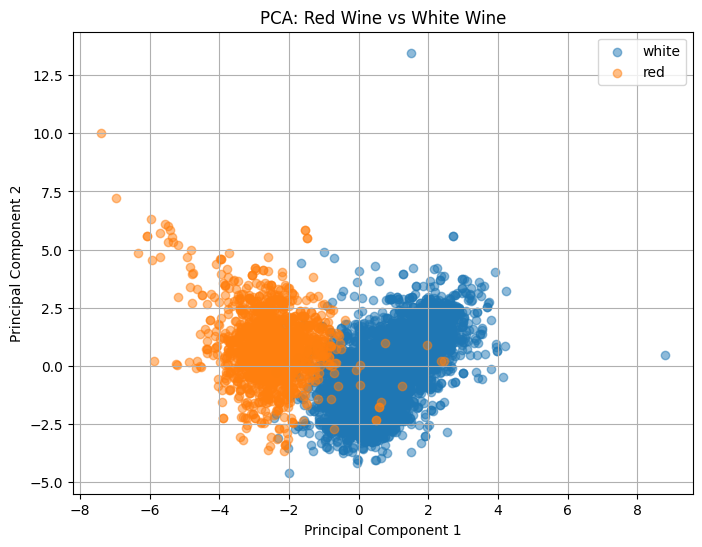

In [15]:
# Plot PCA results
plt.figure(figsize=(8, 6))

for wine in pca_df['Wine Type'].unique():

    data = pca_df[pca_df['Wine Type'] == wine]

    plt.scatter(
        data['PC1'],
        data['PC2'],
        label=wine,
        alpha=0.5
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA: Red Wine vs White Wine")

plt.legend()
plt.grid()

plt.show()